# Hierarchical Bayesian Kalman Filter Model (Bandit Task)
This notebook implements a Hierarchical Bayesian Kalman Filter model on the four-armed bandit task behavioral data. We test whether generalized anxiety symptoms (measured via GAD-7 scores) predict learning parameters:
1. **Process Noise $Q$ (Drift Variance):** How fast subject-level beliefs about card rewards drift/fluctuate over time.
2. **Observation Noise $R$ (Measurement Variance):** How volatile/noisy card reward feedback is assumed to be by the subject.

The subject-level parameters are modeled as log-linear functions of GAD-7:
- $Q_{sub} = \exp(\text{int}_Q + \text{slope}_Q \cdot \text{GAD7}_{normalized})$
- $R_{sub} = \exp(\text{int}_R + \text{slope}_R \cdot \text{GAD7}_{normalized})$

We run sampling using JAX-backed NUTS (`numpyro`) and analyze the credible intervals (89% HDI) of the slopes.


In [1]:
import pandas as pd
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt
import arviz as az
import warnings

from learning_functions import prepare_vectorized_bandit_data, step_kalman_vec, get_hdi_bounds, plot_posterior_hdi

warnings.filterwarnings('ignore')


In [2]:
# Load Data and Vectorize across Subjects
file_path = '../data/allsubs_combined.csv'
df_raw = pd.read_csv(file_path).dropna(subset=['ChoiceKey', 'GAD7']).reset_index(drop=True).copy()

stim_map = {'W1': 0, 'W2': 1, 'L1': 2, 'L2': 3}
df_raw['LeftID_int'] = df_raw['LeftID'].map(stim_map)
df_raw['RightID_int'] = df_raw['RightID'].map(stim_map)
df_raw['ChosenID_int'] = df_raw['ChosenID'].map(stim_map)
df_raw['Choice'] = (df_raw['ChoiceKey'] - 1).astype(int)
df_raw['RewardScaled'] = df_raw['TrialPoints'] / 30.0

vdata = prepare_vectorized_bandit_data(df_raw)
df = vdata['df']
n_sub = vdata['n_sub']
unique_subs = vdata['unique_subs']

sub_gad7_map = df.groupby('SubIdx')['GAD7'].first()
gad7_scores = np.array([sub_gad7_map[i] for i in range(n_sub)])
gad7_normalized = gad7_scores / 21.0

print(f"Total subjects included: {n_sub}")
print(f"Total trials: {len(df)} (Vectorized scan length: {vdata['max_t']} steps)")


Total subjects included: 67
Total trials: 6520 (Vectorized scan length: 100 steps)


In [3]:
# Using vectorized step_kalman_vec from learning_functions.py


In [4]:
def build_kalman_model(vdata, gad7_normalized):
    n_sub, t_idx, s_idx = vdata['n_sub'], vdata['t_idx'], vdata['s_idx']
    with pm.Model() as kf_model:
        gad7_data = pm.Data("gad7_data", gad7_normalized)
        
        int_Q = pm.Normal('int_Q', mu=-2, sigma=1)
        slope_Q = pm.Normal('slope_Q', mu=0, sigma=1.5)
        Q_sub = pm.Deterministic('Q_sub', pm.math.exp(int_Q + slope_Q * gad7_data))
        
        int_R = pm.Normal('int_R', mu=-1, sigma=1)
        slope_R = pm.Normal('slope_R', mu=0, sigma=1.5)
        R_sub = pm.Deterministic('R_sub', pm.math.exp(int_R + slope_R * gad7_data))
        
        mu_beta_log = pm.Normal('mu_beta_log', mu=1, sigma=1)
        sigma_beta = pm.HalfNormal('sigma_beta', sigma=0.5)
        beta_raw = pm.Normal('beta_raw', mu=0, sigma=1, shape=n_sub)
        beta = pm.Deterministic('beta', pm.math.exp(mu_beta_log + beta_raw * sigma_beta))
        
        mu_init = pt.zeros((n_sub, 4)) + 0.5
        sigma2_init = pt.ones((n_sub, 4)) * 1.0
        
        results = pytensor.scan(
            fn=step_kalman_vec,
            sequences=[
                pt.as_tensor_variable(vdata['left_oh']),
                pt.as_tensor_variable(vdata['right_oh']),
                pt.as_tensor_variable(vdata['chosen_oh']),
                pt.as_tensor_variable(vdata['rew_mat']),
                pt.as_tensor_variable(vdata['valid_mat']),
            ],
            outputs_info=[mu_init, sigma2_init, None, None],
            non_sequences=[Q_sub, R_sub],
            strict=True,
            return_updates=False
        )
        q_left_seq = results[2][t_idx, s_idx]
        q_right_seq = results[3][t_idx, s_idx]
        p_right_raw = pm.math.sigmoid(beta[s_idx] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        pm.Bernoulli('choice_obs', p=p_right, observed=vdata['df']['Choice'].values)
    return kf_model

print("Building Vectorized Hierarchical Kalman Filter model...")
kf_model = build_kalman_model(vdata, gad7_normalized)


Building Vectorized Hierarchical Kalman Filter model...


In [5]:
print("Sampling posterior using nutpie (PyMC 6)...")
with kf_model:
    idata = pm.sample(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=True)
print("Sampling complete!")


Sampling posterior using nutpie (PyMC 6)...


NUTS[nutpie]: [int_Q, slope_Q, int_R, slope_R, mu_beta_log, sigma_beta, beta_raw]


Output()

Sampling complete!


KALMAN FILTER GAD-7 REGRESSION RESULTS (89% HDI)
Slope Q (Process Noise / Drift) HDI 89%: [-0.708, 2.403] -> INCLUDES 0 (Not strictly credible at 89%)
Slope R (Observation Noise / Volatility) HDI 89%: [-0.573, 1.101] -> INCLUDES 0 (Not strictly credible at 89%)



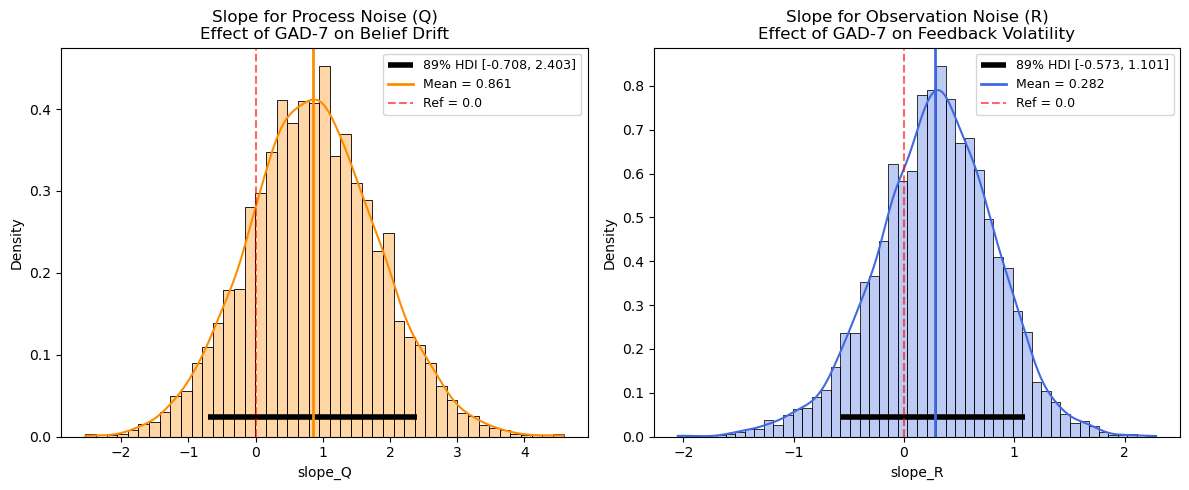

In [6]:
sq_low, sq_high = get_hdi_bounds(idata, 'slope_Q', prob=0.89)
sr_low, sr_high = get_hdi_bounds(idata, 'slope_R', prob=0.89)

def check_credibility(low, high, param_name):
    includes_zero = (low <= 0) and (high >= 0)
    status = "INCLUDES 0 (Not strictly credible at 89%)" if includes_zero else "EXCLUDES 0 (Credible effect at 89%)"
    print(f"{param_name} HDI 89%: [{low:.3f}, {high:.3f}] -> {status}")

print("==================================================")
print("KALMAN FILTER GAD-7 REGRESSION RESULTS (89% HDI)")
print("==================================================")
check_credibility(sq_low, sq_high, "Slope Q (Process Noise / Drift)")
check_credibility(sr_low, sr_high, "Slope R (Observation Noise / Volatility)")
print("==================================================\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_posterior_hdi(idata, 'slope_Q', prob=0.89, ax=axes[0], color="darkorange", title="Slope for Process Noise (Q)\nEffect of GAD-7 on Belief Drift")
plot_posterior_hdi(idata, 'slope_R', prob=0.89, ax=axes[1], color="royalblue", title="Slope for Observation Noise (R)\nEffect of GAD-7 on Feedback Volatility")
plt.tight_layout()
plt.show()
